# Case Study 20 — Predicting the Value of a New Customer Before Their First Order: Zero-Inflated LTV, Ranking Metrics and Bid Optimisation

**Priority:** ★★★ Must-visit · **Reference:** Case Study 20 — *Swiggy: predicted customer lifetime value (pLTV) for acquisition bidding* (`indian_ecommerce_data_science_case_studies.md`)
**Audience:** Head of Growth / Performance Marketing, Data Science, Finance, Product (Food and Instamart)
**Data:** ⚠️ **SYNTHETIC** (D-20-01). Swiggy's customer data is confidential; this is a calibrated simulation with hidden ground truth.
**Evidence level:** Medium (the source is an InfoQ report of Swiggy's own post; the original post was not readable). Swiggy has not disclosed dataset size, split scheme, layer sizes or lift figures. This notebook is an interview-standard solution on simulated data, not a reproduction of Swiggy's results.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs20_customer_lifetime_value.ipynb`

## 0. Executive Summary for Business

*(Synthetic new-customer data with hidden true value, built on Swiggy's documented use of a predicted lifetime value (pLTV) model for acquisition bidding. Swiggy's data, model sizes and lift figures are not public and are not reproduced; this is an interview-standard solution on simulated data.)*

- **The question:** can we predict, before a new customer's first order, how much they will spend in 180 days, and does bidding on that prediction beat flat bids and a short-term "will they order in 30 days" model?
- **The target is hard.** 40.0% of customers spend nothing in 180 days, order counts are heavily over-dispersed (dispersion index 10.9, Poisson would be 1), and the top 10% of customers hold 58.1% of value (Gini 0.754). Mean value is ₹1,573 against a median of ₹436.
- **Ranking is moderate.** On the latest eight weeks, the best model (OLS on log value) reaches a **Spearman of 0.469** (95% CI 0.451 to 0.484), the hurdle GBM 0.456, the multi-task MLP 0.452. The segment-mean model a competing bidder could build reaches only **0.228**, and the vendor-like 30-day model **0.241**. All gaps to the best model are significant after Holm correction, but the gap between the top four models is small (0.008 to 0.042).
- **Ranking and level are different skills.** The best ranker is badly calibrated (predicted total 6.8× actual). Only the hurdle GBM (ratio 0.96) and the raw-value GBM (1.04) get the level about right.
- **Bidding at equal spend:** the OLS-log model buys **2,630 customers at ₹2,873 GOV each, ROAS 49.1**, against flat bidding at ROAS 38.7 (4,553 customers at ₹1,304) and the vendor-like model at 40.9. The ROAS gain over flat bids is **+10.4** (CI 7.9 to 12.6, Holm p = 0.02). The share of acquired customers who never order falls from 45.7% to 19.8%.
- **Multi-task did not help here.** The multi-task MLP uses half the parameters of two separate nets (14,498 vs 28,930) and scores the same total Spearman (0.4489 vs 0.4495, paired p = 0.81 on three seeds, low power).
- **Money (assumed ₹200 crore a year, 8% margin):** about **₹166 crore a year of extra contribution** over flat bids (CI ₹127 to ₹201 crore). The absolute level depends on simulated ROAS and should not be quoted as a forecast.
- **I recommend:** bid on a ranked pLTV score, use a calibrated model (hurdle or raw-value GBM) wherever a rupee level is needed, keep the 30-day model only as an early indicator, and run a randomised bidding holdout (about 7,200 customers per arm to see a 10% difference).

## 1. The Problem in Simple English

When we pay to acquire a new app user (a Google ad click, an Instagram install), we do not know yet whether that person will order once and disappear or order every week for a year. Most acquisition systems bid for the **short-term outcome** (an install, a first order). That favours cheap, low-quality users. If we could **predict, before the first order, how much a user will be worth over the next six months**, we could bid more for the valuable users and less for the rest.

Three things make this hard:
1. **Cold start.** Before the first order we have no purchase history, so the usual tools (RFM scores, BG/NBD purchase-count models) do not apply. We only have *signals*: channel, device, location, browsing, coupon use, fraud risk.
2. **A strange target.** Many new users never order (here about 40% within six months), while a small group orders a lot (the top 10% of customers carry about 58% of value). Averages and "percent error" are misleading.
3. **It is a ranking and bidding problem.** The model does not need to guess each rupee exactly. It needs to rank users well enough that **bids differ in the right direction**.

Leaders and interviewers want to know:
1. How should we judge a model for a zero-inflated, heavy-tailed target (and why not MAE or MAPE)?
2. Which model families work, and does a hurdle structure or a neural network matter?
3. Is the model calibrated and stable across channels and over time?
4. What does it do to acquisition **profit and ROAS** compared with flat bidding and with a vendor's short-term model?
5. How would we prove it in an A/B test when the outcome takes six months to mature?

## 2. Reference from the Case File

### (a) What Swiggy did — *documented* (second-hand, via InfoQ)

| Item | Documented fact (from the reference file) |
|---|---|
| Problem | Predict long-term value of new customers across **Food and Instamart before their first order**, so ad bids optimise long-term value, not short-term conversion. Early signals are sparse and the target is skewed: many new users place no orders in 30 days while a small group has much higher LTV |
| Features | **350+** pre-first-order features: acquisition channel, device and fraud signals, geographic behaviour, complaint history, Instamart category affinity, order behaviour, payment patterns, socio-economic indicators. Dataset size and time range: ND |
| Model | **Multi-task MLP**: three shared hidden layers, task heads for Food and Instamart; parameters cut from 363,000 to 135,000 ("63% reduction"); a four-head version was marginally better. Layer sizes/activations: ND. Target: LTV (primary), order count (auxiliary) |
| Evaluation | MAE and MAPE judged insufficient (many zeros, long tail). Predicted and actual values split into **ten quantiles**; **Spearman above 0.75** for both Food and Instamart; **diagonal coverage 70% to 80%**. Split scheme and hypothesis tests: ND |
| Use | Output feeds **Google tROAS bidding**; next step: probabilistic pLTV for uncertainty |
| Decision / impact | Use the in-house pLTV signal instead of a third-party pLTV platform. In a production A/B the in-house model gave "higher retention and gross order value per acquired user, with no additional platform costs"; the external platform **acquired more users per dollar**. Exact figures: ND |

**Source:** InfoQ, "Swiggy Uses 350+ Features and Multi-Task MLP to Predict Customer Lifetime Value", Leela Kumili, 2 Sep 2026 (original Swiggy Bytes post not read). Classic RFM segmentation at Nykaa/Myntra/FirstCry/Flipkart: no company source found.

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 60,000 new customers over 52 weekly cohorts; about 60 pre-first-order features (a few strong, many weak, 20 pure noise; **Swiggy used 350+**, we cannot replicate that); 180-day gross order value (GOV) for Food and Instamart; hurdle structure with a heavy tail; channel mix drifting over time |
| Models compared | (1) channel × city × OS segment mean (what competing bidders can see); (2) OLS on log value; (3) **hurdle gradient boosting** (P(order) × value if active); (4) gradient boosting on raw value; (5) gradient boosting on log value; (6) **multi-task MLP** with Food and Instamart heads; (7) a **vendor-like** short-term model (restricted features, predicts P(order within 30 days)) |
| Statistics added | **Ranking metrics** (Spearman with bootstrap CI, decile diagonal coverage, top-decile capture, normalised Gini) beside MAE/MAPE; **paired bootstrap** comparisons with Holm; **calibration** (ratio of totals, slope, decile table); feature screening with **BH** (including noise features); stability over time and by channel; **auction simulation** at equal spend with bootstrap CIs; A/B **sample size** |
| Numbers | Every metric here is **simulated**. Our Spearman is not comparable with Swiggy's reported 0.75; it depends on how strong our assumed signals are |

### (c) How the industry uses this

Marketing teams at Indian consumer apps (Swiggy, Zomato, Nykaa, Myntra, Flipkart, Meesho) value acquisition by predicted LTV: pLTV models feed tROAS/value-based bidding in Google and Meta, budget allocation by channel, and CRM targeting. After the first order, simpler models (RFM, BG/NBD with Gamma-Gamma, cohort curves) take over. It is among the most-asked growth data-science interview topics: cold start, zero-inflated targets, calibration, "how do you validate it when LTV takes six months?".

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Can pre-first-order information rank new users by future value well enough to differentiate ad bids and raise return on acquisition spend? |
| Analytical | Which model best ranks users by 180-day value out of time, is it calibrated and stable, and how much does it change ROAS at equal spend against flat bidding, segment-average bidding and a short-term vendor model? |

**Hypotheses**
- **H1 (target):** H0: early orders (first 30 days) carry no information about 180-day value; value is not concentrated (Gini = 0).
- **H2 (signal):** H0: each pre-order feature is unrelated to value (Spearman / Kruskal, Benjamini-Hochberg across about 60 features; 20 are pure noise by construction).
- **H3 (ranking):** H0: the best model's Spearman equals each alternative's on the same customers (paired bootstrap, Holm).
- **H4 (calibration):** H0: predicted total value equals actual total value (ratio = 1, bootstrap CI).
- **H5 (stability):** H0: ranking quality is the same in the latest cohorts as in the validation cohorts and across channels.
- **H6 (decision):** H0: bidding on the model gives the same ROAS at equal spend as flat bidding / the vendor-like model (paired bootstrap).

**Primary metric:** Spearman rank correlation between predicted and actual 180-day GOV on a **time-ordered hold-out** (latest cohorts). **Decision metric:** GOV per ₹ of acquisition spend (ROAS) at equal budget. **Diagnostics:** top-decile value capture, diagonal coverage, calibration ratio.

In [1]:
import sys, warnings, importlib, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public Indian food/quick-commerce customer-level LTV data | **None.** Public customer-value datasets (Online Retail UCI, CDNow, Olist, Instacart) are non-Indian retail transactions, have no pre-first-order signals and no ad-auction side. |
| **Decision** | Synthetic new customers with pre-first-order signals, a hidden hurdle-style value process and an auction side table, so that bidding can be simulated at equal spend (D-20-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs20.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 20 (predicted lifetime value of new customers for bid optimisation)
========================================================================================================
THIS DATA IS SYNTHETIC. Swiggy's customer data is confidential.

Documented context (InfoQ report of Swiggy's own post, 2 Sep 2026; the original post was not readable): predict
long-term value of NEW customers across Food and Instamart BEFORE the first order, from 350+ pre-first-order features
(acquisition channel, device and fraud signals, geography, complaint history, Instamart category affinity, payment
patterns, socio-economic indicators). Many new users place no order within 30 days while a small group generates much
higher lifetime value (zero-inflated, long tail). Model: multi-task MLP, 3 shared hidden layers, heads for Food and
Instamart; evaluated by decile ranking (Spearman > 0.75, diagonal coverage 70-80%); output feeds Google tROAS bidding.
Dataset size, time range, split scheme, layer sizes and lift figures are NOT public (ND).

Simulation: 60,000 new customers over 52 weekly signup cohorts, about 60 pre-first-order features (a handful drive
value, most are weak or pure noise), 180-day gross order value (GOV) for Food and Instamart, hurdle structure
(P(no order) about one third; heavy-tailed value given active). The channel mix drifts over time (more influencer
traffic late in the year). An ad-auction side table gives the competing clearing price per acquired customer,
priced from COARSE signals only (channel, city tier, OS, device tier), so a model with richer pre-order features
has an information edge. Hidden ground-truth columns are prefixed with "_".

Outputs: data/cs20/customers.csv.gz
"""
import os
import numpy as np
import pandas as pd

SEED = 42
N = 60_000; WEEKS = 52
CHANNELS = ["organic", "google_uac", "meta", "referral", "influencer", "cashback_affiliate"]
CH_ACT = np.array([0.35, 0.10, 0.00, 0.45, -0.20, -0.55]); CH_FREQ = np.array([0.20, 0.05, -0.05, 0.25, -0.10, -0.35])


def _sig(x):
    return 1 / (1 + np.exp(-x))


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    week = np.sort(rng.integers(0, WEEKS, N)); frac = week / (WEEKS - 1)
    p_ch = np.array([0.30 - 0.12 * frac, 0.25 + 0.0 * frac, 0.20 - 0.02 * frac, 0.10 + 0.0 * frac, 0.05 + 0.12 * frac, 0.10 + 0.02 * frac]).T; p_ch = p_ch / p_ch.sum(1, keepdims=True)
    ch = (p_ch.cumsum(1) < rng.random(N)[:, None]).sum(1)
    os_ios = (rng.random(N) < np.where(ch == 2, 0.35, 0.22)).astype(int); city = rng.choice([1, 2, 3], N, p=[0.45, 0.33, 0.22]); e = rng.normal(0, 1, N); a = rng.normal(0, 1, N)
    aff = np.clip(55 - 9 * (city - 1) + 8 * os_ios + rng.normal(0, 14, N), 0, 100); aff_z = (aff - 50) / 18
    tier = np.clip(np.rint(2 + 0.6 * aff_z + 0.5 * os_ios + rng.normal(0, 0.7, N)), 1, 3).astype(int)
    fraud = np.clip(_sig(-2.4 + 1.6 * (ch == 5) + 0.9 * (ch == 4) + rng.normal(0, 1.1, N)), 0, 1)
    coupon = (rng.random(N) < _sig(-0.4 + 0.9 * (ch == 5) + 0.5 * (ch == 2) + 0.2 * e)).astype(int); referral = (ch == 3).astype(int) | (rng.random(N) < 0.03)
    hour = np.clip(np.rint(rng.normal(19, 4.5, N)), 0, 23).astype(int); dow = rng.integers(0, 7, N); dist = np.exp(rng.normal(np.log(2.2), 0.55, N)) * np.where(city == 3, 1.5, 1.0)
    sessions = rng.poisson(np.exp(1.0 + 0.5 * e)); searches = rng.poisson(np.exp(0.4 + 0.6 * e)); cart = rng.poisson(np.exp(-0.2 + 0.7 * e)); cart_val = np.round(cart * np.exp(rng.normal(5.7 + 0.2 * aff_z, 0.5, N)), 0)
    first_min = np.exp(rng.normal(1.2 + 0.3 * e, 0.6)); food_share = _sig(-0.4 * a + rng.normal(0, 0.8, N)); rest_view = rng.poisson(np.exp(1.2 + 0.4 * e - 0.2 * a)); rest_price = np.exp(rng.normal(np.log(320) + 0.18 * aff_z, 0.25, N))
    insta_cat = {c: rng.poisson(np.exp(-0.4 + 0.55 * a + 0.2 * e + off)) for c, off in (("grocery", 0.5), ("fresh", 0.2), ("snacks", 0.1), ("personal_care", -0.3), ("electronics", -0.9))}
    complaints = rng.poisson(np.exp(-2.2 + 0.25 * (city == 3) + 0.2 * fraud * 3 - 0.2 * e)); pp = np.column_stack([0.55 - 0.1 * (city - 1), 0.20 + 0.1 * os_ios, 0.10 + 0.1 * (city - 1), np.full(N, 0.15)]); pp = pp / pp.sum(1, keepdims=True)
    payment = np.array(["upi", "card", "cod", "wallet"])[np.minimum((pp.cumsum(1) < rng.random(N)[:, None]).sum(1), 3)]
    notif = (rng.random(N) < _sig(0.8 + 0.3 * e)).astype(int); loc_prec = (rng.random(N) < _sig(0.9 + 0.2 * e)).astype(int); contacts = np.exp(rng.normal(5.2 + 0.2 * e, 0.8, N)); density = np.exp(rng.normal(3.0 - 0.4 * (city - 1), 0.5, N))
    install_gap = np.exp(rng.normal(2.0 - 0.3 * e, 1.0, N)); app_ver = rng.integers(0, 4, N)
    # ---- hidden value structure
    logit_act = 0.55 + 0.85 * e + 0.35 * coupon + 0.30 * referral + CH_ACT[ch] - 2.6 * fraud - 0.18 * (dist - 2.2) + 0.25 * aff_z + 0.18 * notif + 0.12 * loc_prec - 0.12 * np.minimum(complaints, 3) + 0.02 * np.minimum(cart, 5)
    p_act = _sig(logit_act); active180 = rng.random(N) < p_act; active30 = active180 & (rng.random(N) < 0.80)
    frailty = rng.normal(0, 0.75, N); log_mu = np.log(2.2) + 0.50 * e + 0.30 * a + CH_FREQ[ch] + 0.25 * aff_z + 0.10 * (tier - 2) - 0.10 * (dist - 2.2) / 2 + frailty
    mu = np.exp(log_mu); k = 1.6; n_extra = rng.negative_binomial(k, k / (k + mu)); n_ord = np.where(active180, 1 + n_extra, 0)
    q_ins = _sig(-1.3 + 0.9 * a + 0.2 * aff_z + 0.6 * np.log1p(insta_cat["grocery"] + insta_cat["fresh"]) * 0.3)
    uid = np.repeat(np.arange(N), n_ord); is_ins = rng.random(len(uid)) < q_ins[uid]
    base_food = np.exp(np.log(340) + 0.15 * aff_z + 0.06 * (tier - 2)); base_ins = np.exp(np.log(560) + 0.20 * aff_z + 0.06 * (tier - 2))
    val = np.where(is_ins, base_ins[uid], base_food[uid]) * np.exp(rng.normal(0, 0.45, len(uid)))
    food = np.bincount(uid, weights=np.where(is_ins, 0, val), minlength=N); ins = np.bincount(uid, weights=np.where(is_ins, val, 0), minlength=N); o30 = np.bincount(uid, weights=(rng.random(len(uid)) < np.where(active30[uid], 0.45, 0.0)).astype(float), minlength=N)
    orders30 = np.where(active30, np.minimum(np.maximum(1, np.rint(o30)), n_ord), 0).astype(int)
    ltv = food + ins
    # ---- competitor clearing price (auction), from COARSE signals only
    coarse = np.exp(0.9 * CH_ACT[ch] + 0.6 * CH_FREQ[ch] + 0.18 * (3 - city) + 0.12 * os_ios + 0.08 * (tier - 2)); coarse = coarse / coarse.mean() * 1500
    clearing = 0.040 * coarse * np.exp(rng.normal(0, 0.55, N))
    df = pd.DataFrame({
        "customer_id": np.arange(N), "signup_week": week, "channel": np.array(CHANNELS)[ch], "os_ios": os_ios, "device_price_tier": tier, "city_tier": city, "signup_hour": hour, "signup_dow": dow,
        "payment_pref": payment, "referral_used": referral.astype(int), "coupon_first_session": coupon, "notification_opt_in": notif, "location_precise": loc_prec, "app_version_bucket": app_ver,
        "first_session_minutes": np.round(first_min, 2), "sessions_pre": sessions, "searches_pre": searches, "cart_adds_pre": cart, "cart_value_pre_inr": cart_val, "food_browse_share": np.round(food_share, 3),
        "restaurants_viewed": rest_view, "avg_restaurant_price_viewed": np.round(rest_price, 0), **{f"insta_views_{c}": v for c, v in insta_cat.items()}, "distance_nearest_store_km": np.round(dist, 2),
        "pincode_affluence_index": np.round(aff, 1), "pincode_order_density": np.round(density, 2), "fraud_score": np.round(fraud, 3), "complaints_pre": complaints, "contacts_book_size": np.round(contacts, 0), "install_to_signup_hours": np.round(install_gap, 2),
        **{f"noise_{i:02d}": rng.normal(0, 1, N).round(3) for i in range(1, 21)},
        "orders_30d": orders30, "orders_180d": n_ord, "food_ltv_180d": np.round(food, 0), "insta_ltv_180d": np.round(ins, 0), "ltv_180d": np.round(ltv, 0),
        "_latent_intent": np.round(e, 3), "_p_active": np.round(p_act, 4), "_active180": active180.astype(int), "_clearing_price_inr": np.round(clearing, 1), "_coarse_value_inr": np.round(coarse, 0)})
    # data-quality defects
    big = rng.choice(N, 36, replace=False); bulk = np.round(rng.uniform(150_000, 600_000, 36), 0); df.loc[big, "ltv_180d"] = bulk; df.loc[big, "food_ltv_180d"] = bulk     # bulk / corporate accounts
    bad = rng.choice(N, 14, replace=False); df.loc[bad, "ltv_180d"] = -np.abs(df.loc[bad, "ltv_180d"]) - 100                                                 # refunds booked as negative
    df.loc[rng.choice(N, int(0.06 * N), replace=False), "device_price_tier"] = np.nan; df.loc[rng.choice(N, int(0.04 * N), replace=False), "pincode_affluence_index"] = np.nan
    df.loc[rng.choice(N, int(0.02 * N), replace=False), "fraud_score"] = np.nan
    df = pd.concat([df, df.sample(n=600, random_state=seed)], ignore_index=True).sample(frac=1, random_state=seed).reset_index(drop=True)
    return df


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs20"), exist_ok=True)
    d = generate(); d.to_csv(os.path.join(here, "cs20", "customers.csv.gz"), index=False)
    c = d.drop_duplicates("customer_id"); c = c[(c.ltv_180d >= 0) & (c.ltv_180d < 100_000)]
    print(len(d), "rows |", len(c), "clean | zero in 30d", round((c.orders_30d == 0).mean(), 3), "| zero in 180d", round((c.ltv_180d == 0).mean(), 3), "| mean ltv", round(c.ltv_180d.mean()), "| median", c.ltv_180d.median(), "| P90", c.ltv_180d.quantile(0.9).round())
    s = c.ltv_180d.sort_values(ascending=False); print("top10% share", round(s.head(len(s) // 10).sum() / s.sum(), 3), "| top1% share", round(s.head(len(s) // 100).sum() / s.sum(), 3), "| insta share of value", round(c.insta_ltv_180d.sum() / (c.food_ltv_180d.sum() + c.insta_ltv_180d.sum()), 3))
    print("ltv by channel", c.groupby("channel").ltv_180d.mean().round().to_dict()); print("channel mix wk<10", c[c.signup_week < 10].channel.value_counts(normalize=True).round(3).to_dict(), "wk>=42", c[c.signup_week >= 42].channel.value_counts(normalize=True).round(3).to_dict())
    from scipy.stats import spearmanr
    print("spearman(ltv, p_active)", round(spearmanr(c.ltv_180d, c._p_active)[0], 3), "| spearman(ltv, ltv-coarse)", round(spearmanr(c.ltv_180d, c._coarse_value_inr)[0], 3), "| mean clearing", round(c._clearing_price_inr.mean(), 1), "| corr(orders30, ltv) spearman", round(spearmanr(c.orders_30d, c.ltv_180d)[0], 3))

Overwriting data/generate_cs20.py


In [3]:
os.makedirs("data/cs20", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs20 as gen; importlib.reload(gen)
t0 = time.time(); raw = gen.generate(seed=SEED); raw.to_csv("data/cs20/customers.csv.gz", index=False)
print(f"{len(raw):,} rows x {raw.shape[1]} columns | generated in {time.time() - t0:.0f}s")
raw.iloc[:4, :14]

60,600 rows x 64 columns | generated in 44s


,customer_id,signup_week,channel,os_ios,device_price_tier,city_tier,signup_hour,signup_dow,payment_pref,referral_used,coupon_first_session,notification_opt_in,location_precise,app_version_bucket
0,30627,26,meta,0,2.0000,1,23,2,upi,0,1,1,0,2
1,40402,34,organic,1,2.0000,2,9,6,cod,0,1,1,1,3
2,40105,34,meta,1,2.0000,1,15,4,wallet,0,1,1,0,3
3,32869,28,cashback_affiliate,0,1.0000,3,18,0,upi,1,1,0,1,2


| Parameter | Value | Basis |
|---|---|---|
| Customers | 60,000 over 52 weekly cohorts | Our assumption (Swiggy: ND) |
| Features | about 60 (channel, device, geography, browsing, Instamart category views, payment, fraud, complaints, affluence) plus 20 pure-noise columns | **Documented** categories; **350+** features at Swiggy |
| Target | 180-day GOV (Food + Instamart); about 40% never order, 52% have no order in the first 30 days (**documented** concern: many zeros) | Our assumption |
| Heavy tail | Order counts overdispersed (negative binomial) with customer-level frailty; top 10% of customers ≈ 58% of value | Our assumption (documented: "small group much higher") |
| Drift | Influencer share rises from 6% to 15% of signups over the year | Our assumption |
| Auction | Competitors' clearing price = 4% of a **coarse** value (channel, city, OS, device tier) × lognormal noise (σ = 0.55); mean ≈ ₹70 per customer | Our assumption (second-price auction) |
| DQ issues | 600 duplicate rows; 36 bulk/corporate accounts (₹1.5–6 lakh); 14 negative values (refunds); missing values in device tier (6%), affluence (4%), fraud score (2%) | Built-in messiness |

### 4.3 Data dictionary

#### Code

In [4]:
dd = pd.DataFrame([
    ("customer_id, signup_week", "Customer and weekly signup cohort 0–51"),
    ("channel, os_ios, device_price_tier, city_tier, signup_hour, signup_dow", "Acquisition and device context (known at install)"),
    ("payment_pref, referral_used, coupon_first_session, notification_opt_in, location_precise, app_version_bucket", "Payment and first-session signals"),
    ("first_session_minutes, sessions_pre, searches_pre, cart_adds_pre, cart_value_pre_inr, food_browse_share, restaurants_viewed, avg_restaurant_price_viewed", "Browsing before the first order"),
    ("insta_views_grocery / fresh / snacks / personal_care / electronics", "Instamart category affinity (views)"),
    ("distance_nearest_store_km, pincode_affluence_index, pincode_order_density, fraud_score, complaints_pre, contacts_book_size, install_to_signup_hours", "Geography, socio-economic, risk and support signals"),
    ("noise_01 … noise_20", "Pure noise (used to test false discoveries)"),
    ("orders_30d, orders_180d, food_ltv_180d, insta_ltv_180d, ltv_180d", "OUTCOMES (never used as features): orders and GOV"),
    ("_latent_intent, _p_active, _active180, _clearing_price_inr, _coarse_value_inr", "HIDDEN: latent intent, activation probability, auction clearing price, coarse value"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs20/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"customer_id, signup_week",Customer and weekly signup cohort 0–51
1,"channel, os_ios, device_price_tier, city_tier,...",Acquisition and device context (known at install)
2,"payment_pref, referral_used, coupon_first_sess...",Payment and first-session signals
3,"first_session_minutes, sessions_pre, searches_...",Browsing before the first order
4,insta_views_grocery / fresh / snacks / persona...,Instamart category affinity (views)
5,"distance_nearest_store_km, pincode_affluence_i...","Geography, socio-economic, risk and support si..."
6,noise_01 … noise_20,Pure noise (used to test false discoveries)
7,"orders_30d, orders_180d, food_ltv_180d, insta_...",OUTCOMES (never used as features): orders and GOV
8,"_latent_intent, _p_active, _active180, _cleari...","HIDDEN: latent intent, activation probability,..."


## 5. Data Quality Checks

In [5]:
chk = {"rows": len(raw), "duplicate customer rows": int(raw.duplicated("customer_id").sum()), "negative LTV (refund booked)": int((raw.ltv_180d < 0).sum()), "bulk accounts (LTV > ₹1 lakh)": int((raw.ltv_180d > 1e5).sum()),
       "share of all value in bulk accounts": float(raw.loc[raw.ltv_180d > 1e5, "ltv_180d"].sum() / raw.loc[raw.ltv_180d > 0, "ltv_180d"].sum()), "missing device_price_tier": int(raw.device_price_tier.isna().sum()),
       "missing pincode_affluence_index": int(raw.pincode_affluence_index.isna().sum()), "missing fraud_score": int(raw.fraud_score.isna().sum())}
print(pd.Series(chk, name="value").to_string())
C = raw.drop_duplicates("customer_id"); n_before = len(C); C = C[(C.ltv_180d >= 0) & (C.ltv_180d <= 1e5)].copy().reset_index(drop=True)
print(f"\nDropped {n_before - len(C)} rows (negative refunds and bulk accounts, which are not ordinary new customers). Clean: {len(C):,} customers | zero 180-day value: {(C.ltv_180d == 0).mean():.1%} | zero orders in 30 days: {(C.orders_30d == 0).mean():.1%} | mean LTV ₹{C.ltv_180d.mean():,.0f} | median ₹{C.ltv_180d.median():,.0f}")
TARG = ["orders_30d", "orders_180d", "food_ltv_180d", "insta_ltv_180d", "ltv_180d"]; HID = [c for c in C.columns if c.startswith("_")]
TR_W, VA_W = 36, 44; trm, vam, tem = (C.signup_week < TR_W).values, ((C.signup_week >= TR_W) & (C.signup_week < VA_W)).values, (C.signup_week >= VA_W).values
print(f"Time-ordered split: train weeks 0-{TR_W - 1}: {trm.sum():,} | validation weeks {TR_W}-{VA_W - 1}: {vam.sum():,} | test weeks {VA_W}-51: {tem.sum():,}")

rows                                  60,600.0000
duplicate customer rows                  600.0000
negative LTV (refund booked)              14.0000
bulk accounts (LTV > ₹1 lakh)             38.0000
share of all value in bulk accounts        0.1217
missing device_price_tier              3,638.0000
missing pincode_affluence_index        2,426.0000
missing fraud_score                    1,215.0000



Dropped 52 rows (negative refunds and bulk accounts, which are not ordinary new customers). Clean: 59,948 customers | zero 180-day value: 40.0% | zero orders in 30 days: 52.1% | mean LTV ₹1,573 | median ₹436
Time-ordered split: train weeks 0-35: 41,560 | validation weeks 36-43: 9,246 | test weeks 44-51: 9,142


**Observation:** of 60,600 rows, **600 were duplicate customers**, **14 had negative lifetime value** (refunds booked) and **38 were bulk accounts** (above ₹1 lakh) that hold **12.2% of all value**. We dropped the negative and bulk accounts (52 rows), leaving **59,948 customers**. Missing values are 3,638 for device tier, 2,426 for the pincode affluence index and 1,215 for the fraud score; these get missing flags rather than deletion. In the clean data **40.0% have zero 180-day value** and **52.1% have no order in 30 days**; mean value is ₹1,573 against a median of ₹436. The time-ordered split gives 41,560 training, 9,246 validation and 9,142 test customers.

## 6. Exploratory Data Analysis

### 6.1 The target: zeros, a long tail and concentration

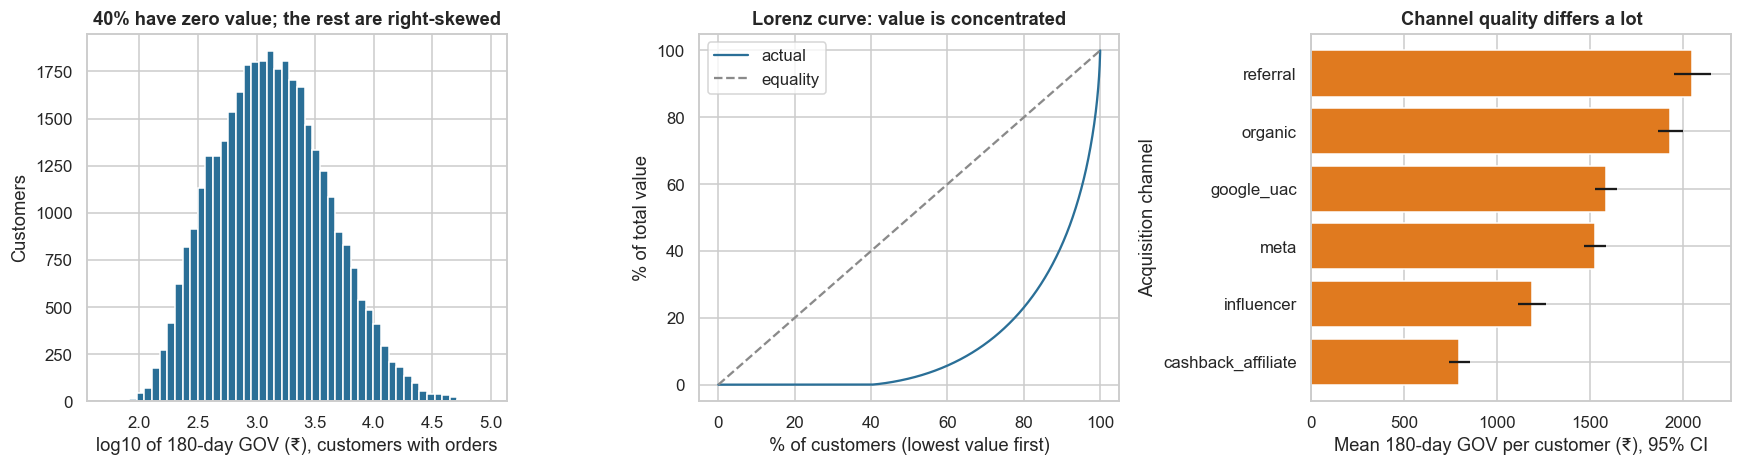

Top 10% of customers = 58.1% of value | top 1% = 16.9% | Gini = 0.754 | best channel ₹2,050 vs worst ₹796


In [6]:
y = C.ltv_180d.values; fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
pos = y[y > 0]; axes[0].hist(np.log10(pos), bins=50, color="#2a6f97"); axes[0].set_xlabel("log10 of 180-day GOV (₹), customers with orders"); axes[0].set_ylabel("Customers"); axes[0].set_title(f"{(y == 0).mean():.0%} have zero value; the rest are right-skewed")
srt = np.sort(y); lor = np.cumsum(srt) / srt.sum(); xs = np.arange(1, len(srt) + 1) / len(srt); axes[1].plot(xs * 100, lor * 100, color="#2a6f97", label="actual"); axes[1].plot([0, 100], [0, 100], "--", color="#8a8a8a", label="equality"); axes[1].set_xlabel("% of customers (lowest value first)"); axes[1].set_ylabel("% of total value"); axes[1].set_title("Lorenz curve: value is concentrated"); axes[1].legend()
g = C.groupby("channel").ltv_180d.agg(["mean", "std", "count"]).sort_values("mean"); g["ci"] = 1.96 * g["std"] / np.sqrt(g["count"]); axes[2].barh(g.index, g["mean"], xerr=g.ci, color="#e07a1f"); axes[2].set_xlabel("Mean 180-day GOV per customer (₹), 95% CI"); axes[2].set_ylabel("Acquisition channel"); axes[2].set_title("Channel quality differs a lot")
plt.tight_layout(); plt.show()
print(f"Top 10% of customers = {np.sort(y)[::-1][:len(y) // 10].sum() / y.sum():.1%} of value | top 1% = {np.sort(y)[::-1][:len(y) // 100].sum() / y.sum():.1%} | Gini = {1 - 2 * np.trapezoid(lor, xs):.3f} | best channel ₹{g['mean'].max():,.0f} vs worst ₹{g['mean'].min():,.0f}")

**Takeaway:** value is **extremely concentrated**: the top 10% of customers hold **58.1%** of value and the top 1% hold **16.9%** (Gini 0.754). The best channel averages **₹2,050** per customer against **₹796** for the worst. A flat bid ignores this spread, and a model scored on average error would be driven by a handful of very large customers.

### 6.2 Time: channel mix drift and the early-order signal

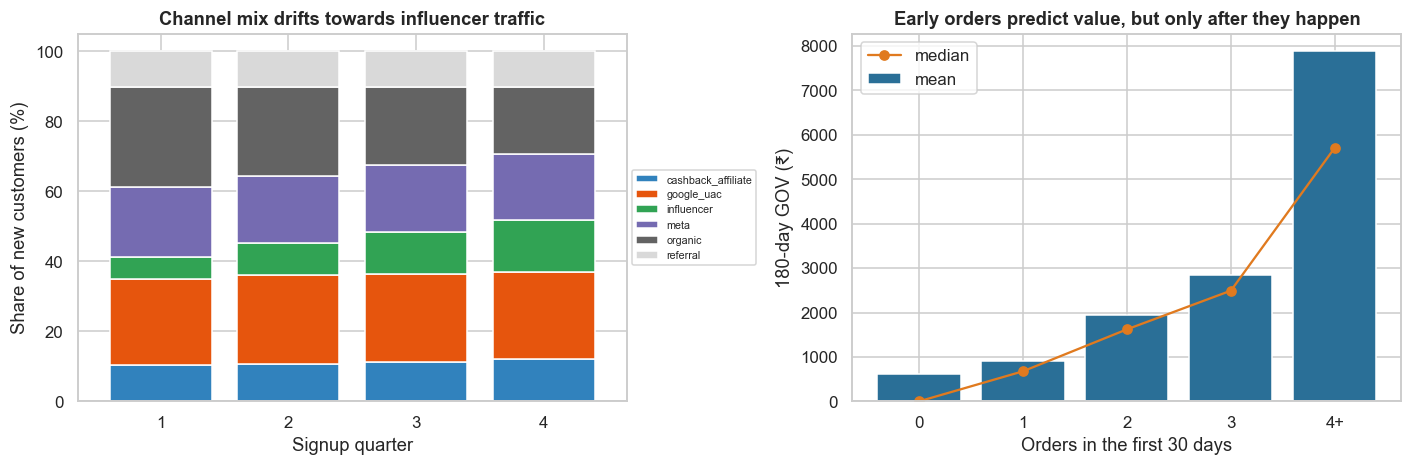

Customers with no order in 30 days who still order later: 7,251 (23.2% of the zero-30-day group); they hold 20.3% of all value


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4)); C["quarter"] = C.signup_week // 13 + 1
mix = pd.crosstab(C.quarter, C.channel, normalize="index") * 100; mix.plot(kind="bar", stacked=True, ax=axes[0], colormap="tab20c", width=0.8); axes[0].set_xlabel("Signup quarter"); axes[0].set_ylabel("Share of new customers (%)"); axes[0].set_title("Channel mix drifts towards influencer traffic"); axes[0].legend(fontsize=7, loc="center left", bbox_to_anchor=(1.0, 0.5)); axes[0].tick_params(axis="x", rotation=0)
b30 = C.orders_30d.clip(upper=4); gm = C.groupby(b30).ltv_180d.agg(["mean", "median"]); axes[1].bar(gm.index.astype(str).str.replace("4", "4+"), gm["mean"], color="#2a6f97", label="mean"); axes[1].plot(range(len(gm)), gm["median"], "o-", color="#e07a1f", label="median"); axes[1].set_xlabel("Orders in the first 30 days"); axes[1].set_ylabel("180-day GOV (₹)"); axes[1].set_title("Early orders predict value, but only after they happen"); axes[1].legend()
plt.tight_layout(); plt.show()
late = C[(C.orders_30d == 0) & (C.ltv_180d > 0)]; print(f"Customers with no order in 30 days who still order later: {len(late):,} ({len(late) / (C.orders_30d == 0).sum():.1%} of the zero-30-day group); they hold {late.ltv_180d.sum() / C.ltv_180d.sum():.1%} of all value")

**Takeaway:** the 30-day signal is useful but not enough: **7,251 customers (23.2% of those with no order in 30 days) still order later**, and they hold **20.3% of all value**. A model built only on 30-day conversion would undervalue them.

## 7. Statistical Analysis (core section)

### 7.1 Anatomy of the target: is it really zero-inflated and heavy-tailed?

**(a) Why?** The choice of loss, metric and model depends on the shape of the target. We test: **zero inflation** (share of zeros, Wilson CI), **overdispersion** of order counts (variance ≫ mean means a plain Poisson fails), **heavy tail** (top-decile share and Gini with bootstrap CIs; skewness; a normal-on-log test of positive values), and the **early signal** (Spearman between 30-day orders and 180-day value, with a bootstrap CI).
- **Hypotheses:** H0: dispersion index = 1; H0: Gini = 0; H0: log-values are normal (Shapiro-Wilk on a 5,000 sample); H0: 30-day orders and 180-day value are uncorrelated.

#### Code

In [8]:
from statsmodels.stats.proportion import proportion_confint
n_ = len(C); z0 = (y == 0).sum(); lo_, hi_ = proportion_confint(z0, n_, method="wilson"); oa = C.loc[C.orders_180d > 0, "orders_180d"]
def gini(v): s = np.sort(v); c = np.cumsum(s) / s.sum(); return 1 - 2 * np.trapezoid(c, np.arange(1, len(s) + 1) / len(s))
def topshare(v, f=0.10): s = np.sort(v)[::-1]; return s[:int(len(s) * f)].sum() / s.sum()
bs = [(gini(y[i]), topshare(y[i])) for i in (RNG.integers(0, n_, n_) for _ in range(300))]; bsr = [stats.spearmanr(C.orders_30d.values[i], y[i])[0] for i in (RNG.integers(0, n_, n_) for _ in range(300))]
lp = np.log(pos); sh = stats.shapiro(RNG.choice(lp, 5000, replace=False)); rho30 = stats.spearmanr(C.orders_30d, y)[0]
print(f"Zero 180-day value: {z0 / n_:.1%} (95% CI {lo_:.1%} to {hi_:.1%})")
print(f"Orders per active customer: mean {oa.mean():.2f}, variance {oa.var():.2f}, dispersion index {oa.var() / oa.mean():.2f} (Poisson = 1) | max {oa.max()}")
print(f"Gini {gini(y):.3f} (95% CI {np.percentile([b[0] for b in bs], 2.5):.3f} to {np.percentile([b[0] for b in bs], 97.5):.3f}) | top-10% share {topshare(y):.1%} (CI {np.percentile([b[1] for b in bs], 2.5):.1%} to {np.percentile([b[1] for b in bs], 97.5):.1%})")
print(f"Positive values: skewness {stats.skew(pos):.2f}; log-values skewness {stats.skew(lp):.2f}; Shapiro-Wilk on logs W = {sh.statistic:.3f}, p = {sh.pvalue:.2g} | mean/median of positives {pos.mean() / np.median(pos):.2f}")
print(f"Spearman(30-day orders, 180-day GOV) = {rho30:.3f} (95% CI {np.percentile(bsr, 2.5):.3f} to {np.percentile(bsr, 97.5):.3f}); share of top-decile customers with zero orders in 30 days: {(C.orders_30d.values[y >= np.quantile(y, 0.9)] == 0).mean():.1%}")
pd.DataFrame({"value": [z0 / n_, oa.var() / oa.mean(), gini(y), topshare(y), rho30]}, index=["zero share", "dispersion index", "Gini", "top-10% share", "Spearman 30d vs 180d"]).round(3)

Zero 180-day value: 40.0% (95% CI 39.6% to 40.4%)
Orders per active customer: mean 5.30, variance 57.55, dispersion index 10.86 (Poisson = 1) | max 180
Gini 0.754 (95% CI 0.751 to 0.757) | top-10% share 58.1% (CI 57.5% to 58.7%)
Positive values: skewness 6.59; log-values skewness 0.26; Shapiro-Wilk on logs W = 0.993, p = 2.6e-15 | mean/median of positives 2.00
Spearman(30-day orders, 180-day GOV) = 0.755 (95% CI 0.750 to 0.760); share of top-decile customers with zero orders in 30 days: 20.4%


,value
zero share,0.4000
dispersion index,10.8570
Gini,0.7540
top-10% share,0.5810
Spearman 30d vs 180d,0.7550


**Observation:** **(c)** The target is heavy-tailed and zero-inflated. Zeros are **40.0%** (95% CI 39.6% to 40.4%). Orders among active customers have a mean of 5.30 and a variance of 57.55, a **dispersion index of 10.9**, so a plain Poisson is rejected. The Gini is **0.754** (CI 0.751 to 0.757) and the top-decile share **58.1%** (CI 57.5% to 58.7%). Positive values have skewness 6.59, which falls to 0.26 on the log scale; the Shapiro-Wilk test still rejects normality of the logs (W = 0.993, p = 2.6e-15), but W is close to 1, so the departure is small. The Spearman correlation between 30-day orders and 180-day value is **0.755** (CI 0.750 to 0.760), strong but not perfect, and 20.4% of the top-decile customers had no order in 30 days. We therefore use log-type or hurdle models and rank-based metrics, not a plain squared-error fit in rupees.

### 7.2 Which pre-order signals carry information? Feature screening with false-discovery control

**(a) Why?** We have about 60 candidate signals including **20 pure-noise columns**. Testing 60 features at 5% would give about 3 false positives by chance. We use **Spearman rank correlation** (numeric) or **Kruskal-Wallis** (categorical) against 180-day value on the **training** weeks only, and compare uncorrected, Holm and **Benjamini-Hochberg** decisions. A good screen flags real signals and few noise columns. We also run a Kruskal-Wallis test of value across channels with Holm-adjusted Mann-Whitney comparisons to organic.
- **Hypotheses:** H0: the feature has no monotone/group association with value; H0: all channels have the same value distribution.

#### Code

In [9]:
CATS = ["channel", "payment_pref"]; NUM = [c for c in C.columns if c not in TARG + HID + CATS + ["customer_id", "signup_week", "quarter"]]
Ctr = C[trm]; rows = []
for c in NUM:
    v = Ctr[[c, "ltv_180d"]].dropna(); r, p = stats.spearmanr(v[c], v.ltv_180d); rows.append((c, "numeric", r, p, c.startswith("noise_")))
for c in CATS:
    gs = [g.ltv_180d.values for _, g in Ctr.groupby(c)]; h, p = stats.kruskal(*gs); eta = (h - len(gs) + 1) / (len(Ctr) - len(gs)); rows.append((c, "categorical", np.sqrt(max(eta, 0)), p, False))
fs = pd.DataFrame(rows, columns=["feature", "type", "effect (|rho| or sqrt(eta²_H))", "p", "is_noise"]).set_index("feature"); fs["p_holm"] = multipletests(fs.p, method="holm")[1]; fs["p_BH"] = multipletests(fs.p, method="fdr_bh")[1]
sm_ = pd.DataFrame({"flagged": [(fs.p < 0.05).sum(), (fs.p_holm < 0.05).sum(), (fs.p_BH < 0.05).sum()], "of which noise": [((fs.p < 0.05) & fs.is_noise).sum(), ((fs.p_holm < 0.05) & fs.is_noise).sum(), ((fs.p_BH < 0.05) & fs.is_noise).sum()]}, index=["uncorrected p < 0.05", "Holm", "Benjamini-Hochberg"])
print(f"{len(fs)} features screened on {len(Ctr):,} training customers ({int(fs.is_noise.sum())} are pure noise)"); print(sm_.to_string())
print("\nStrongest signals (effect size, BH-adjusted p):"); print(fs.sort_values("effect (|rho| or sqrt(eta²_H))", key=lambda v: v.abs(), ascending=False).head(10)[["effect (|rho| or sqrt(eta²_H))", "p_BH"]].round(4).to_string())
kw = stats.kruskal(*[g.ltv_180d.values for _, g in C.groupby("channel")]); org = C[C.channel == "organic"].ltv_180d.values; pw = []
for ch_, g in C.groupby("channel"):
    if ch_ == "organic": continue
    pw.append((ch_, len(g), g.ltv_180d.mean(), g.ltv_180d.mean() / org.mean() - 1, stats.mannwhitneyu(g.ltv_180d.values, org).pvalue))
pw = pd.DataFrame(pw, columns=["channel vs organic", "customers", "mean value (₹)", "relative to organic", "Mann-Whitney p"]).set_index("channel vs organic"); pw["p_holm"] = multipletests(pw["Mann-Whitney p"], method="holm")[1]
print(f"\nKruskal-Wallis across 6 channels: H = {kw.statistic:.0f}, p = {kw.pvalue:.2g}"); pw.round(4)

52 features screened on 41,560 training customers (20 are pure noise)
                      flagged  of which noise
uncorrected p < 0.05       33               4
Holm                       28               0
Benjamini-Hochberg         30               1

Strongest signals (effect size, BH-adjusted p):
                           effect (|rho| or sqrt(eta²_H))   p_BH
feature                                                         
sessions_pre                                       0.2456 0.0000
searches_pre                                       0.2309 0.0000
cart_adds_pre                                      0.2218 0.0000
cart_value_pre_inr                                 0.2217 0.0000
pincode_affluence_index                            0.2011 0.0000
restaurants_viewed                                 0.1906 0.0000
channel                                            0.1858 0.0000
first_session_minutes                              0.1755 0.0000
fraud_score                                    


Kruskal-Wallis across 6 channels: H = 2150, p = 0


,customers,mean value (₹),relative to organic,Mann-Whitney p,p_holm
channel vs organic,,,,,
cashback_affiliate,6665,796.2738,-0.5875,0.0000,0.0000
google_uac,14945,"1,585.7336",-0.1786,0.0000,0.0000
influencer,6397,"1,187.4699",-0.3849,0.0000,0.0000
meta,11541,"1,526.0691",-0.2095,0.0000,0.0000
referral,6108,"2,050.1377",0.0620,0.0000,0.0000


**Observation:** **(c)** Screening 52 features (20 of them pure noise) on training weeks: uncorrected testing flags **33 features, 4 of them noise**; **Holm flags 28 with 0 noise**; Benjamini-Hochberg flags 30 with 1 noise. The strongest signals are early browsing and cart behaviour (sessions_pre 0.246, searches_pre 0.231, cart_adds_pre 0.222), pincode affluence (0.201), channel (0.186) and, negatively, fraud score (-0.156). Channels differ strongly (Kruskal-Wallis H = 2,150). Against organic, every other channel is significantly different after Holm correction: cashback and affiliate **-59%** (₹796), influencer -38%, meta -21%, google_uac -18% and referral **+6%** (₹2,050). Effect sizes are modest for single features, so no one feature will carry the model.

### 7.3 Setup and results: seven models, ranking metrics and why MAE misleads

**(a) Why?** All models see **only pre-first-order information** (no 30-day orders, no outcomes). They are fitted on training weeks, tuned/scaled with validation weeks only where noted (smearing and scale factors), and scored on the **latest weeks (test)**.

| # | Model | In one line |
|---|---|---|
| 1 | Segment mean | Mean 180-day value by channel × city tier × OS (all a competing bidder can see) |
| 2 | OLS on log value | Linear model of log(1 + value), back-transformed with a smearing factor |
| 3 | Hurdle GBM | Gradient boosting classifier for P(any order) × boosting regressor for log value among those who order |
| 4 | GBM on raw value | Squared-error boosting on rupees |
| 5 | GBM on log value | Boosting on log(1 + value), smeared |
| 6 | Multi-task MLP | Three shared hidden layers (96-64-32), two heads (Food and Instamart log value), as documented in structure |
| 7 | Vendor-like | Restricted features (channel, OS, device tier, city, hour, weekday) and a classifier of **P(order within 30 days)**, a short-term target |

**Ranking metrics (test weeks):** Spearman; **top-decile capture** (share of total value held by the 10% of customers the model scores highest; the oracle's share is the ceiling); **normalised Gini** (Gini of the ranking divided by the oracle's); **decile diagonal coverage** (share of customers whose predicted decile equals the actual decile, and within ±1; zeros are tied, so the strict figure cannot reach 100%: the ceiling shown is an oracle with random tie-breaking); and, for contrast, **MAE** and **MAPE on customers with orders**.

#### Code

In [10]:
def build_X(df, med):
    X = df[NUM].copy()
    for c in ("device_price_tier", "pincode_affluence_index", "fraud_score"): X[c + "_missing"] = X[c].isna().astype(float)
    X = X.fillna(med)
    for ch_ in gen.CHANNELS: X["ch_" + ch_] = (df.channel == ch_).astype(float)
    for p_ in ("upi", "card", "cod", "wallet"): X["pay_" + p_] = (df.payment_pref == p_).astype(float)
    return X.astype(float)
MED = C.loc[trm, NUM].median(); X = build_X(C, MED); FEATS = list(X.columns); print(f"{len(FEATS)} model features ({len(NUM)} raw + missing flags + channel and payment indicators)")
Y = C.ltv_180d.values.astype(float); Yf, Yi = C.food_ltv_180d.values.astype(float), C.insta_ltv_180d.values.astype(float); act = (Y > 0).astype(int); y30 = (C.orders_30d.values > 0).astype(int)
S = {}; PAR = {}; t0 = time.time()
seg = C[trm].groupby(["channel", "city_tier", "os_ios"]).ltv_180d.mean(); S["1 segment mean (channel x city x OS)"] = np.array([seg.get((a, b, c), Y[trm].mean()) for a, b, c in zip(C.channel, C.city_tier, C.os_ios)])
ols = LinearRegression().fit(X[trm], np.log1p(Y[trm])); sm_ols = np.mean(np.exp(np.log1p(Y[vam]) - ols.predict(X[vam]))); S["2 OLS on log value"] = np.maximum(np.exp(ols.predict(X)) * sm_ols - 1, 0)
gb = dict(max_iter=250, learning_rate=0.05, max_depth=4, l2_regularization=1.0, random_state=SEED)
clf = HistGradientBoostingClassifier(**gb).fit(X[trm], act[trm]); pm = trm & (Y > 0); reg = HistGradientBoostingRegressor(**gb).fit(X[pm], np.log(Y[pm])); vp = vam & (Y > 0); sm_h = np.mean(np.exp(np.log(Y[vp]) - reg.predict(X[vp])))
p_hat = clf.predict_proba(X)[:, 1]; S["3 hurdle GBM"] = p_hat * np.exp(reg.predict(X)) * sm_h
rawm = HistGradientBoostingRegressor(**gb).fit(X[trm], Y[trm]); S["4 GBM on raw value"] = np.maximum(rawm.predict(X), 0)
logm = HistGradientBoostingRegressor(**gb).fit(X[trm], np.log1p(Y[trm])); sm_l = np.mean(np.exp(np.log1p(Y[vam]) - logm.predict(X[vam]))); S["5 GBM on log value"] = np.maximum(np.exp(logm.predict(X)) * sm_l - 1, 0)
sc = StandardScaler().fit(X[trm]); Xs = sc.transform(X); YY = np.log1p(np.column_stack([Yf, Yi]))
def fit_mlp(cols, seed, hidden=(96, 64, 32)):
    m = MLPRegressor(hidden_layer_sizes=hidden, alpha=1e-3, batch_size=256, early_stopping=True, validation_fraction=0.1, n_iter_no_change=8, max_iter=80, random_state=seed); m.fit(Xs[trm], YY[trm][:, cols] if len(cols) > 1 else YY[trm][:, cols[0]]); return m
def n_params(m): return sum(w.size for w in m.coefs_) + sum(b.size for b in m.intercepts_)
mt = fit_mlp([0, 1], SEED); pr = np.expm1(mt.predict(Xs)).clip(min=0); cal = Y[vam].sum() / pr[vam].sum(); S["6 multi-task MLP (Food + Instamart heads)"] = pr.sum(1) * cal; PAR["mt"] = (mt, cal)
VR = ["os_ios", "device_price_tier", "city_tier", "signup_hour", "signup_dow"] + ["ch_" + c for c in gen.CHANNELS]; vend = HistGradientBoostingClassifier(max_iter=120, learning_rate=0.05, max_depth=3, random_state=SEED).fit(X.loc[trm, VR], y30[trm]); S["7 vendor-like (P(order in 30 days), restricted features)"] = vend.predict_proba(X[VR])[:, 1]
print(f"fitted in {time.time() - t0:.0f}s | MLP: {mt.n_iter_} epochs, {n_params(mt):,} parameters | smearing factors: OLS {sm_ols:.2f}, hurdle {sm_h:.2f}, GBM-log {sm_l:.2f} | MLP scale {cal:.2f}")
yt = Y[tem]; nt = len(yt); jit = np.random.default_rng(1).random(nt)
def dec(v, jt): o = np.lexsort((jt, v)); r = np.empty(nt, int); r[o] = np.arange(nt); return (r * 10 // nt)
ad = dec(yt, jit)
def norm_gini(sc_, yv): o = np.argsort(sc_, kind="stable"); c = np.cumsum(yv[o]) / yv.sum(); g_ = 1 - 2 * np.trapezoid(c, np.arange(1, len(yv) + 1) / len(yv)); return g_ / gini(yv)
def evalm(sc_, yv=yt):
    pdc = dec(sc_, np.random.default_rng(2).random(nt)); top = np.argsort(-sc_, kind="stable")[: nt // 10]
    return dict(spearman=stats.spearmanr(sc_, yv)[0], top_decile_capture=yv[top].sum() / yv.sum(), norm_gini=norm_gini(sc_, yv), diag_strict=(pdc == ad).mean(), diag_within1=(np.abs(pdc - ad) <= 1).mean())
res = pd.DataFrame({k: evalm(v[tem]) for k, v in S.items()}).T
orc_dec = dec(yt, np.random.default_rng(3).random(nt)); orc = dict(strict=(orc_dec == ad).mean(), w1=(np.abs(orc_dec - ad) <= 1).mean(), top=np.sort(yt)[::-1][: nt // 10].sum() / yt.sum())
med_tr = np.median(Y[trm]); mae = {"constant: training median": np.abs(yt - med_tr).mean(), "constant: training mean": np.abs(yt - Y[trm].mean()).mean()}
for k, v in S.items(): mae[k] = np.abs(yt - v[tem]).mean() if k[0] not in "7" else np.nan
res["MAE (₹)"] = [mae[k] for k in res.index]; res["MAPE on customers with orders"] = [np.mean(np.abs(yt[yt > 0] - v[tem][yt > 0]) / yt[yt > 0]) if k[0] != "7" else np.nan for k, v in S.items()]
print(f"Test customers: {nt:,} | oracle ceilings: top-decile capture {orc['top']:.1%}, strict diagonal {orc['strict']:.1%}, within ±1 {orc['w1']:.1%} | constant-median MAE ₹{mae['constant: training median']:.0f}, constant-mean MAE ₹{mae['constant: training mean']:.0f}")
res.round(4)

63 model features (50 raw + missing flags + channel and payment indicators)


fitted in 663s | MLP: 13 epochs, 14,498 parameters | smearing factors: OLS 19.08, hurdle 1.62, GBM-log 19.80 | MLP scale 1.99
Test customers: 9,142 | oracle ceilings: top-decile capture 57.8%, strict diagonal 68.5%, within ±1 83.4% | constant-median MAE ₹1451, constant-mean MAE ₹1807


,spearman,top_decile_capture,norm_gini,diag_strict,diag_within1,MAE (₹),MAPE on customers with orders
1 segment mean (channel x city x OS),0.2282,0.1593,0.2596,0.1192,0.3353,"1,716.3844",1.4182
2 OLS on log value,0.4685,0.2970,0.5447,0.1605,0.4138,"9,708.5960",8.7493
3 hurdle GBM,0.4555,0.3169,0.5839,0.1621,0.4141,"1,472.2232",1.2064
4 GBM on raw value,0.4264,0.3125,0.5662,0.1612,0.4014,"1,535.7759",1.2898
5 GBM on log value,0.4606,0.3008,0.5374,0.1581,0.4081,"4,137.2214",4.8142
6 multi-task MLP (Food + Instamart heads),0.4523,0.2963,0.5346,0.1605,0.4125,"1,423.9379",0.9328
"7 vendor-like (P(order in 30 days), restricted features)",0.2409,0.1493,0.2736,0.1279,0.3414,NaN,NaN


**Observation:** **(c)** Ranking quality on the test weeks: **OLS on log value is best on Spearman (0.469)**, then GBM on log value (0.461), hurdle GBM (0.456), multi-task MLP (0.452) and GBM on raw value (0.426). The segment-mean model (0.228) and the vendor-like 30-day model (0.241) are far behind. On top-decile capture and normalised Gini the **hurdle GBM is best** (31.7% and 0.584) against 29.7% and 0.545 for OLS, while the oracle ceiling for capture is 57.8%, so even the best model captures only about half of what is possible. Strict decile hits are only 12% to 16% (ceiling 68.5%), and within one decile 33% to 41% (ceiling 83.4%). **MAE misleads**: the OLS model has the best ranking but an MAE of ₹9,709, far worse than the constant-mean predictor (₹1,807), because a few huge back-transformed predictions dominate; the MLP has the lowest MAE (₹1,424). Choosing by MAE would pick a different model from choosing by ranking.

### 7.4 Is the best model really better? Paired bootstrap on the same customers

**(a) Why?** Models are scored on the **same test customers**, so differences should be tested in pairs. We resample customers 400 times, recompute Spearman for every model on each resample, and test the best model's Spearman minus each other's with a two-sided bootstrap p-value (2 × the smaller tail), adjusted by **Holm**. A bootstrap with 400 resamples cannot resolve p below about 0.005.
- **Hypotheses:** H0: Spearman(best) = Spearman(other).

#### Code

In [11]:
names = list(S); bestm = res.spearman.idxmax(); B = 400; sp = np.zeros((B, len(names))); idxs = [RNG.integers(0, nt, nt) for _ in range(B)]
for j, k in enumerate(names):
    st = S[k][tem]
    for b, ix in enumerate(idxs): sp[b, j] = stats.spearmanr(st[ix], yt[ix])[0]
bi = names.index(bestm); rows = []
for j, k in enumerate(names):
    ci = (np.percentile(sp[:, j], 2.5), np.percentile(sp[:, j], 97.5))
    if j == bi: rows.append((k, res.loc[k, "spearman"], *ci, np.nan, np.nan, np.nan, np.nan)); continue
    d = sp[:, bi] - sp[:, j]; p = min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()) + 1 / B); rows.append((k, res.loc[k, "spearman"], *ci, d.mean(), np.percentile(d, 2.5), np.percentile(d, 97.5), p))
pt = pd.DataFrame(rows, columns=["model", "Spearman", "CI low", "CI high", f"Δ vs best ({bestm[:14]})", "Δ CI low", "Δ CI high", "bootstrap p"]).set_index("model"); mk_ = pt["bootstrap p"].notna(); pt.loc[mk_, "p_holm"] = multipletests(pt.loc[mk_, "bootstrap p"], method="holm")[1]
print(f"Best model by Spearman: {bestm}"); pt.round(4)

Best model by Spearman: 2 OLS on log value


,Spearman,CI low,CI high,Δ vs best (2 OLS on log v),Δ CI low,Δ CI high,bootstrap p,p_holm
model,,,,,,,,
1 segment mean (channel x city x OS),0.2282,0.2084,0.2467,0.2404,0.2219,0.2601,0.0025,0.0150
2 OLS on log value,0.4685,0.4514,0.4839,NaN,NaN,NaN,NaN,NaN
3 hurdle GBM,0.4555,0.4370,0.4721,0.0129,0.0047,0.0211,0.0075,0.0150
4 GBM on raw value,0.4264,0.4089,0.4441,0.0421,0.0305,0.0529,0.0025,0.0150
5 GBM on log value,0.4606,0.4435,0.4767,0.0079,0.0025,0.0130,0.0025,0.0150
6 multi-task MLP (Food + Instamart heads),0.4523,0.4350,0.4690,0.0162,0.0100,0.0227,0.0025,0.0150
"7 vendor-like (P(order in 30 days), restricted features)",0.2409,0.2205,0.2600,0.2278,0.2101,0.2479,0.0025,0.0150


**Observation:** **(c)** The best model's lead is statistically real but small among the top four. Spearman minus the others (paired bootstrap, 400 resamples, Holm): hurdle GBM **+0.013** (CI 0.005 to 0.021), GBM on log value +0.008 (CI 0.003 to 0.013), MLP +0.016, GBM on raw value +0.042, and the segment-mean and vendor-like models about **+0.23 to +0.24**. All Holm p-values are 0.015. The bootstrap cannot resolve p below about 0.0025, so these are "p below 0.015" statements, not exact values. The practical reading is that all learned models beat the simple baselines by a large margin and differ little from each other.

### 7.5 Calibration and decile structure

**(a) Why?** A bidding system multiplies the prediction by a rate, so the **level** must be right, not only the order. We check (i) the **ratio of predicted to actual total value** on the test weeks with a bootstrap CI (H0: ratio = 1), (ii) the **calibration slope** from regressing actual value on the prediction (H0: slope = 1; robust SE), and (iii) a **decile table** of mean predicted vs mean actual value, for the expected-value models.

#### Code

Calibration on test weeks:
                                           predicted / actual total  CI low  CI high  calibration slope  slope CI low  slope CI high  p (slope = 1)
model                                                                                                                                              
2 OLS on log value                                           6.8467  4.5092  10.4608             0.0007       -0.0002         0.0016         0.0000
3 hurdle GBM                                                 0.9645  0.9282   1.0039             1.1337        1.0113         1.2560         0.0323
5 GBM on log value                                           3.1695  3.0113   3.3407             0.1059        0.0858         0.1261         0.0000
6 multi-task MLP (Food + Instamart heads)                    0.2653  0.2370   0.2990             0.1969        0.0339         0.3599         0.0000
4 GBM on raw value                                           1.0363  0.9947   1.0764 

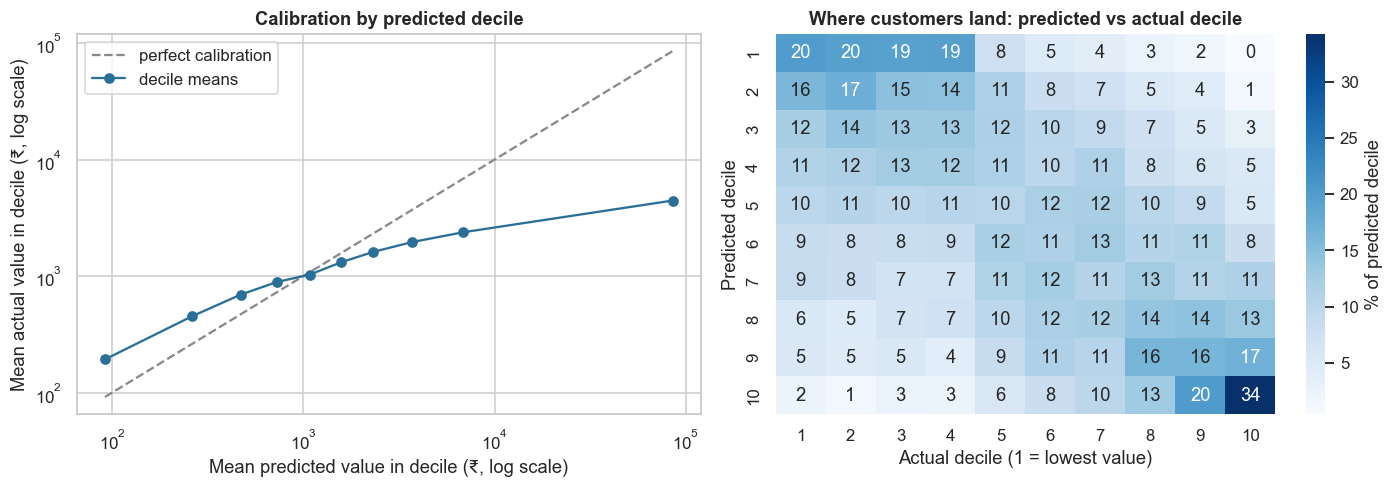

In [12]:
EV = [k for k in names if k[0] in "2356"] + [k for k in names if k[0] == "4"]; rows = []
for k in EV:
    p_ = S[k][tem]; ratio = p_.sum() / yt.sum(); bsr_ = [p_[ix].sum() / yt[ix].sum() for ix in idxs]; fit = sm.OLS(yt, sm.add_constant(p_)).fit(cov_type="HC1"); sl = fit.params[1]; se = fit.bse[1]
    rows.append((k, ratio, np.percentile(bsr_, 2.5), np.percentile(bsr_, 97.5), sl, sl - 1.96 * se, sl + 1.96 * se, stats.norm.sf(abs((sl - 1) / se)) * 2))
cb = pd.DataFrame(rows, columns=["model", "predicted / actual total", "CI low", "CI high", "calibration slope", "slope CI low", "slope CI high", "p (slope = 1)"]).set_index("model"); print("Calibration on test weeks:"); print(cb.round(4).to_string())
bp = S[bestm][tem]; dq = pd.qcut(pd.Series(bp).rank(method="first"), 10, labels=False); dt = pd.DataFrame({"decile": dq + 1, "pred": bp, "act": yt}).groupby("decile").agg(pred=("pred", "mean"), act=("act", "mean"), zero_share=("act", lambda v: (v == 0).mean()))
print(f"\nDecile table for {bestm}:"); print(dt.round(1).T.to_string())
cm = pd.crosstab(dec(bp, np.random.default_rng(2).random(nt)) + 1, ad + 1, normalize="index") * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6)); axes[0].plot([dt.pred.min(), dt.pred.max()], [dt.pred.min(), dt.pred.max()], "--", color="#8a8a8a", label="perfect calibration"); axes[0].plot(dt.pred, dt.act, "o-", color="#2a6f97", label="decile means"); axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_xlabel("Mean predicted value in decile (₹, log scale)"); axes[0].set_ylabel("Mean actual value in decile (₹, log scale)"); axes[0].set_title("Calibration by predicted decile"); axes[0].legend()
sns.heatmap(cm, cmap="Blues", annot=True, fmt=".0f", cbar_kws={"label": "% of predicted decile"}, ax=axes[1]); axes[1].set_xlabel("Actual decile (1 = lowest value)"); axes[1].set_ylabel("Predicted decile"); axes[1].set_title("Where customers land: predicted vs actual decile")
plt.tight_layout(); plt.show()

**Takeaway:** **(c)** Ranking and level are different. The OLS-log model predicts **6.8 times** the actual total (CI 4.5 to 10.5) and its calibration slope is about 0.0007; its top decile is predicted at ₹85,381 but is actually ₹4,450. GBM on log value over-predicts 3.2×, and the MLP under-predicts (0.27×). The **hurdle GBM is close to calibrated** (ratio 0.96, CI 0.93 to 1.00; slope 1.13, p = 0.032) and the **raw-value GBM** is also close (ratio 1.04, CI 0.99 to 1.08; slope 1.00, p = 0.94). The decile table shows the OLS model orders customers correctly but with a wildly inflated top end. This does not hurt a bid that uses only the rank and a multiplier tuned to a budget (section 7.7), but it would break any rule that uses the predicted rupees directly.

### 7.6 Stability: later cohorts, channels and drift

**(a) Why?** A model trained on weeks 0–35 is used on future customers. We compare Spearman on the **validation weeks (36–43)** with the **test weeks (44–51)**, check the shift in channel mix (**Population Stability Index**, PSI; above 0.1 is a notable shift, 0.25 a major one), and compute Spearman by channel and city tier with bootstrap CIs. A **Fisher z comparison** of the validation and test Spearman tests whether ranking quality changed.
- **Hypotheses:** H0: validation Spearman = test Spearman; H0: Spearman is the same in every channel.

#### Code

In [13]:
def spear_ci(s, yv, reps=200):
    n = len(yv); bs_ = [stats.spearmanr(s[i], yv[i])[0] for i in (RNG.integers(0, n, n) for _ in range(reps))]; return stats.spearmanr(s, yv)[0], np.percentile(bs_, 2.5), np.percentile(bs_, 97.5)
sB = S[bestm]; r_va = stats.spearmanr(sB[vam], Y[vam])[0]; r_te = stats.spearmanr(sB[tem], Y[tem])[0]; nv, nte = vam.sum(), tem.sum(); zf = (np.arctanh(r_va) - np.arctanh(r_te)) / np.sqrt(1 / (nv - 3) + 1 / (nte - 3)); pz = 2 * stats.norm.sf(abs(zf))
def psi(a, b): a, b = a.clip(1e-4), b.clip(1e-4); return float(((a - b) * np.log(a / b)).sum())
mx = C.groupby([np.where(trm, "train", np.where(vam, "val", "test")), "channel"]).size().unstack(0); mx = mx / mx.sum()
print(f"Best model ({bestm}): Spearman validation {r_va:.3f} vs test {r_te:.3f} (Fisher z = {zf:.2f}, p = {pz:.3f}) | PSI of channel mix: train→validation {psi(mx['train'], mx['val']):.3f}, train→test {psi(mx['train'], mx['test']):.3f}")
rows = []
for var, vals in (("channel", sorted(C.channel.unique())), ("city_tier", [1, 2, 3])):
    for v in vals:
        m_ = tem & (C[var] == v).values; r, lo, hi = spear_ci(sB[m_], Y[m_]); rows.append((var, v, int(m_.sum()), (Y[m_] == 0).mean(), Y[m_].mean(), r, lo, hi))
sg = pd.DataFrame(rows, columns=["variable", "group", "test customers", "zero-value share", "mean value (₹)", "Spearman", "CI low", "CI high"]).set_index(["variable", "group"])
print("\nSpearman by subgroup on test weeks:"); sg.round(3)

Best model (2 OLS on log value): Spearman validation 0.469 vs test 0.468 (Fisher z = 0.04, p = 0.967) | PSI of channel mix: train→validation 0.040, train→test 0.056



Spearman by subgroup on test weeks:


test customers  zero-value share  mean value (₹)  Spearman  CI low  CI high
variable  group                                                                                          
channel   cashback_affiliate            1100            0.6080        719.4250    0.4080  0.3660   0.4520
          google_uac                    2262            0.3910      1,518.0840    0.4260  0.3940   0.4610
          influencer                    1387            0.4940      1,301.8490    0.4410  0.3940   0.4830
          meta                          1726            0.4070      1,523.3540    0.4370  0.3970   0.4730
          organic                       1727            0.3350      1,840.4570    0.4500  0.4150   0.4900
          referral                       940            0.2800      1,970.0930    0.4550  0.3960   0.5060
city_tier 1                             4068            0.3790      1,830.5290    0.4530  0.4270   0.4770
          2                             3001            0.4070      1,441.3170    0.4650  0.4340   0.4940
          3                             2073            0.4920        925.5280    0.4470  0.4150   0.4840

**Observation:** **(c)** The ranking is stable. Spearman on validation weeks is 0.469 and on test weeks 0.468 (Fisher z = 0.04, p = 0.967), and the channel mix barely moved (PSI 0.040 train to validation, 0.056 train to test, below the 0.1 line). By channel the test Spearman ranges from **0.408 (cashback and affiliate) to 0.455 (referral)**, and by city tier from 0.447 to 0.465, with overlapping CIs. The weakest segment is also the largest source of zero-value customers (60.8% zeros), so ranking there matters most for avoiding wasted spend. There is no sign of drift in this simulation, but it is a stationary simulation, so this is not a guarantee for production.

### 7.7 Does it change the decision? Bidding simulation at equal spend, and the A/B-test size

**(a) Why?** The business decision is how much to bid for each user. We simulate a **second-price auction** on the test-week customers: each customer is an ad opportunity with a competitor clearing price (the `_clearing_price_inr`, set from coarse signals only). A strategy bids `m × score`; it wins the customer if the bid ≥ the clearing price and then **pays the clearing price**. We choose each strategy's multiplier m so that **spend equals a fixed budget** (25% of the cost of buying every opportunity), so the comparison is at equal spend. Strategies: flat bid; segment-mean pLTV; the best model; the multi-task MLP; the vendor-like short-term model; and an oracle that knows true value.
- **Metrics:** customers acquired, GOV per customer, **ROAS = GOV / spend**, share of acquired customers with zero orders. 95% CIs by bootstrapping opportunities (200 resamples, budget recomputed each time).
- **Hypotheses:** H0: ROAS(model) = ROAS(flat); H0: ROAS(model) = ROAS(vendor-like); H0: ROAS(model) = ROAS(segment mean). Paired bootstrap p-values, Holm-adjusted.
- **A/B size:** customers per arm needed to detect a 5% or 10% relative difference in GOV per acquired customer (80% power, α = 0.05), from the SD of value among acquired customers.

#### Code

Budget = 25% of the cost of buying all 9,142 opportunities = ₹154,000 (mean clearing price ₹67)
                                 customers acquired    spend (₹)  GOV per customer (₹)  ROAS (GOV per ₹)  share with zero orders
flat bid                                 4,553.0000 153,404.3000            1,303.7400           38.6950                  0.4570
segment-mean pLTV                        4,134.0000 153,860.3000            1,537.4500           41.3090                  0.4070
model: OLS on log value                  2,630.0000 153,950.6000            2,873.0030           49.0810                  0.1980
multi-task MLP                           2,664.0000 153,966.2000            2,790.5180           48.2830                  0.2090
vendor-like (30-day conversion)          4,490.0000 153,974.0000            1,402.2660           40.8910                  0.4360
oracle (true value)                      2,764.0000 153,953.6000            4,212.9690           75.6370                  0.0000




Paired differences (model minus other), equal spend:
                                                            Δ ROAS  CI low  CI high  bootstrap p  Δ customers acquired     CI low     CI high   Δ GOV per customer (₹)  p_holm
comparison                                                                                                                                                                    
model: OLS on log value vs flat bid                        10.3860  7.9190  12.5530       0.0050                 -1923 -2,000.0750 -1,868.7500              1,569.2640  0.0200
model: OLS on log value vs segment-mean pLTV                7.7720  5.7400  10.0050       0.0050                 -1504 -1,584.1250 -1,440.9750              1,335.5530  0.0200
model: OLS on log value vs vendor-like (30-day conversion)  8.1900  6.1380  10.8480       0.0050                 -1860 -1,935.1750 -1,798.9000              1,470.7380  0.0200
model: OLS on log value vs multi-task MLP                   0.7980 -0.2

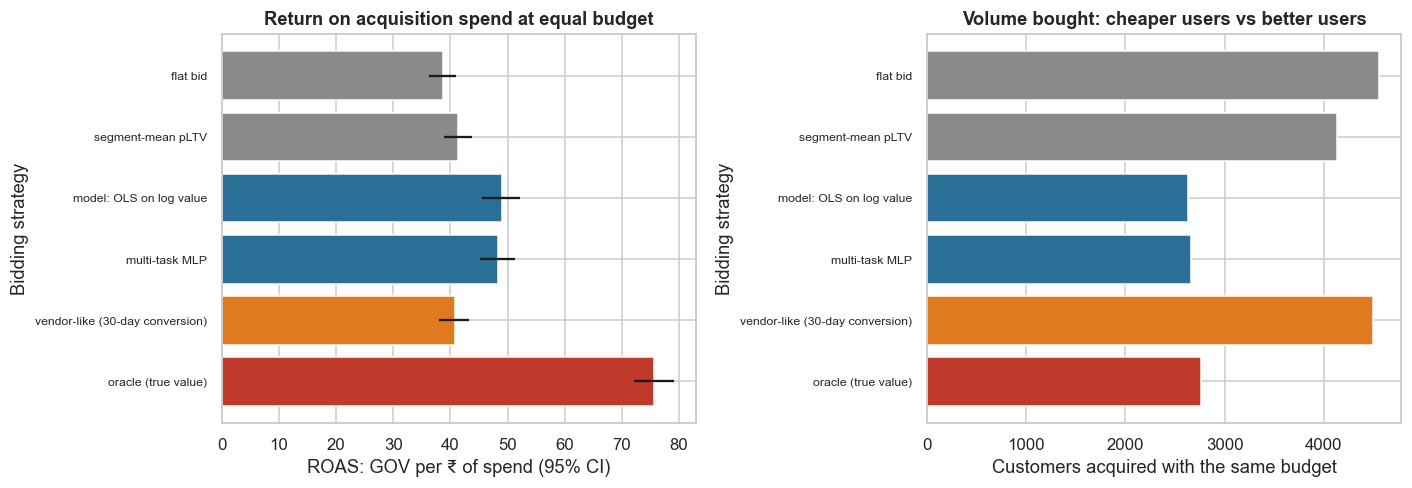

In [14]:
cp_ = C._clearing_price_inr.values[tem]; BF = 0.25
STRAT = {"flat bid": np.ones(nt), "segment-mean pLTV": S[names[0]][tem], f"model: {bestm[2:20]}": S[bestm][tem], "multi-task MLP": S[names[5]][tem], "vendor-like (30-day conversion)": S[names[6]][tem], "oracle (true value)": yt + 1e-6}
def run_auction(score, cp, yv, budget):
    lo, hi = 0.0, 1e6 * max(cp.max() / max(score.max(), 1e-9), 1)
    for _ in range(45):
        mid = (lo + hi) / 2; won = mid * score >= cp
        if cp[won].sum() > budget: hi = mid
        else: lo = mid
    won = lo * score >= cp; sp_ = cp[won].sum(); return won.sum(), sp_, yv[won].sum(), (yv[won] == 0).mean() if won.sum() else np.nan
def summarise_auction(ix):
    cpb, ytb = cp_[ix], yt[ix]; bud = BF * cpb.sum(); out = {}
    for k, sc_ in STRAT.items():
        n_, sp_, g_, z_ = run_auction(sc_[ix], cpb, ytb, bud); out[k] = (n_, sp_, g_ / max(n_, 1), g_ / max(sp_, 1e-9), z_)
    return out
base = summarise_auction(np.arange(nt)); boots = [summarise_auction(ix) for ix in [RNG.integers(0, nt, nt) for _ in range(200)]]
cols_ = ["customers acquired", "spend (₹)", "GOV per customer (₹)", "ROAS (GOV per ₹)", "share with zero orders"]; ab = pd.DataFrame(base, index=cols_).T
for j, c_ in enumerate(cols_[:4]): ab[c_ + " lo"] = [np.percentile([b[k][j] for b in boots], 2.5) for k in STRAT]; ab[c_ + " hi"] = [np.percentile([b[k][j] for b in boots], 97.5) for k in STRAT]
print(f"Budget = {BF:.0%} of the cost of buying all {nt:,} opportunities = ₹{BF * cp_.sum():,.0f} (mean clearing price ₹{cp_.mean():.0f})")
print(ab[cols_].round(3).to_string()); print("\n95% CIs (ROAS, customers acquired):"); print(ab[["ROAS (GOV per ₹) lo", "ROAS (GOV per ₹) hi", "customers acquired lo", "customers acquired hi"]].round(2).to_string())
mk = f"model: {bestm[2:20]}"; rows = []
for other in ("flat bid", "segment-mean pLTV", "vendor-like (30-day conversion)", "multi-task MLP"):
    d = np.array([b[mk][3] - b[other][3] for b in boots]); dn = np.array([b[mk][0] - b[other][0] for b in boots]); dg = np.array([b[mk][2] - b[other][2] for b in boots])
    rows.append((f"{mk} vs {other}", base[mk][3] - base[other][3], np.percentile(d, 2.5), np.percentile(d, 97.5), min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()) + 1 / 200), base[mk][0] - base[other][0], np.percentile(dn, 2.5), np.percentile(dn, 97.5), base[mk][2] - base[other][2]))
dfc = pd.DataFrame(rows, columns=["comparison", "Δ ROAS", "CI low", "CI high", "bootstrap p", "Δ customers acquired", "CI low ", "CI high ", "Δ GOV per customer (₹)"]).set_index("comparison"); dfc["p_holm"] = multipletests(dfc["bootstrap p"], method="holm")[1]
print("\nPaired differences (model minus other), equal spend:"); print(dfc.round(3).to_string())
won_v = (np.argsort(np.argsort(-STRAT["vendor-like (30-day conversion)"])) < base["vendor-like (30-day conversion)"][0]); sd_ = yt.std(); mu_ = yt.mean(); zz = (stats.norm.ppf(0.975) + stats.norm.ppf(0.8)) ** 2
print(f"\nA/B sample size: SD of value among all test customers ₹{sd_:,.0f} vs mean ₹{mu_:,.0f} (SD/mean {sd_ / mu_:.1f}); customers per arm for a 5% difference: {int(np.ceil(2 * zz * sd_ ** 2 / (0.05 * mu_) ** 2)):,}; for 10%: {int(np.ceil(2 * zz * sd_ ** 2 / (0.10 * mu_) ** 2)):,}; Spearman(30-day orders, 180-day value) = {rho30:.2f} (a 30-day proxy is imperfect)")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6)); lab = list(STRAT); xs_ = np.arange(len(lab)); r_ = ab["ROAS (GOV per ₹)"].values; e_ = [r_ - ab["ROAS (GOV per ₹) lo"].values, ab["ROAS (GOV per ₹) hi"].values - r_]
axes[0].barh(xs_, r_, xerr=e_, color=["#8a8a8a", "#8a8a8a", "#2a6f97", "#2a6f97", "#e07a1f", "#c0392b"]); axes[0].set_yticks(xs_); axes[0].set_yticklabels(lab, fontsize=8); axes[0].invert_yaxis(); axes[0].set_xlabel("ROAS: GOV per ₹ of spend (95% CI)"); axes[0].set_ylabel("Bidding strategy"); axes[0].set_title("Return on acquisition spend at equal budget")
nacq = ab["customers acquired"].values; axes[1].barh(xs_, nacq, color=["#8a8a8a", "#8a8a8a", "#2a6f97", "#2a6f97", "#e07a1f", "#c0392b"]); axes[1].set_yticks(xs_); axes[1].set_yticklabels(lab, fontsize=8); axes[1].invert_yaxis(); axes[1].set_xlabel("Customers acquired with the same budget"); axes[1].set_ylabel("Bidding strategy"); axes[1].set_title("Volume bought: cheaper users vs better users")
plt.tight_layout(); plt.show()

**Takeaway:** **(c)** At equal spend (₹154,000, 25% of the cost of buying all 9,142 opportunities), the model-based bid wins fewer, better customers. **OLS-log: 2,630 customers, ₹2,873 GOV each, ROAS 49.1** (CI 45.6 to 52.2), against **flat bid 4,553 customers, ₹1,304, ROAS 38.7** (CI 36.3 to 40.9), segment-mean 41.3, and the vendor-like 30-day model 40.9. An oracle that knows true value reaches 75.6, so the model closes roughly 28% of the gap between a flat bid and the oracle ((49.1-38.7) / (75.6-38.7)). Paired differences in ROAS: **+10.4 vs flat** (CI 7.9 to 12.6), **+7.8 vs segment-mean**, **+8.2 vs vendor-like** (CI 6.1 to 10.8), all Holm p = 0.02. The multi-task MLP is **not distinguishable** from OLS-log (+0.80, CI -0.25 to 1.95, p = 0.175). The share of acquired customers with zero orders falls to 19.8% for the model against 45.7% for flat and 43.6% for the vendor-like model. For a live test, value per customer has SD ₹3,206 against a mean of ₹1,498 (SD/mean 2.1), so detecting a 5% difference needs about **28,778 customers per arm** and a 10% difference **7,195**.

## 8. ML Section — multi-task versus single-task, and what drives the prediction

**(a) Why?** Swiggy documents a multi-task MLP (shared layers, Food and Instamart heads). We test what the multi-task structure buys here: the same network trained **jointly** on both targets versus **two separate single-task networks** with the same layers, over **three seeds** (42, 43, 44), comparing parameters and test Spearman for Food, Instamart and total value. We also compute **permutation importance** (drop in R² on the test weeks when a feature is shuffled) for the log-value gradient-boosting model, to see whether the noise columns are ignored. No tuning: fixed architecture and settings.

#### Code

In [15]:
rows = []; t0 = time.time(); fo, io = Yf[tem], Yi[tem]
for sd in (42, 43, 44):
    m_mt = mt if sd == SEED else fit_mlp([0, 1], sd); m_f = fit_mlp([0], sd); m_i = fit_mlp([1], sd)
    pm_ = np.expm1(m_mt.predict(Xs)).clip(min=0); pf, pi_ = np.expm1(m_f.predict(Xs)).clip(min=0), np.expm1(m_i.predict(Xs)).clip(min=0)
    for nm, a_, b_, npar in (("multi-task", pm_[:, 0], pm_[:, 1], n_params(m_mt)), ("two single-task nets", pf, pi_, n_params(m_f) + n_params(m_i))):
        rows.append((nm, sd, npar, stats.spearmanr(a_[tem], fo)[0], stats.spearmanr(b_[tem], io)[0], stats.spearmanr((a_ + b_)[tem], yt)[0]))
mtt = pd.DataFrame(rows, columns=["setup", "seed", "parameters", "Spearman Food", "Spearman Instamart", "Spearman total"]); smry = mtt.groupby("setup").agg(parameters=("parameters", "first"), food=("Spearman Food", "mean"), food_sd=("Spearman Food", "std"), insta=("Spearman Instamart", "mean"), insta_sd=("Spearman Instamart", "std"), total=("Spearman total", "mean"), total_sd=("Spearman total", "std"))
pdiff = mtt.pivot(index="seed", columns="setup", values="Spearman total"); dseed = pdiff["multi-task"] - pdiff["two single-task nets"]
print(f"Trained in {time.time() - t0:.0f}s"); print(smry.round(4).to_string()); print(f"\nParameter ratio multi-task / two nets: {smry.loc['multi-task', 'parameters'] / smry.loc['two single-task nets', 'parameters']:.2f} | per-seed Δ total Spearman (multi-task − separate): {np.round(dseed.values, 4).tolist()} | mean {dseed.mean():+.4f}, paired t-test p = {stats.ttest_1samp(dseed, 0).pvalue:.2f} (n = 3 seeds, low power)")
pi_res = permutation_importance(logm, X[tem], np.log1p(Y[tem]), n_repeats=3, random_state=SEED, scoring="r2"); imp = pd.Series(pi_res.importances_mean, index=FEATS).sort_values(ascending=False); nz = imp[[f for f in FEATS if f.startswith("noise_")]]
print(f"\nPermutation importance (drop in R² of log value, test weeks). Top 10:"); print(imp.head(10).round(4).to_string()); print(f"Noise columns: largest drop {nz.max():.4f}, mean {nz.mean():.5f}; features with drop > 0.002: {int((imp > 0.002).sum())} of {len(imp)}")
smry.round(4)

Trained in 1468s
                      parameters   food  food_sd  insta  insta_sd  total  total_sd
setup                                                                             
multi-task                 14498 0.4191   0.0028 0.4143    0.0030 0.4489    0.0031
two single-task nets       28930 0.4222   0.0032 0.4134    0.0026 0.4495    0.0016

Parameter ratio multi-task / two nets: 0.50 | per-seed Δ total Spearman (multi-task − separate): [0.0022, 0.0006, -0.0046] | mean -0.0006, paired t-test p = 0.81 (n = 3 seeds, low power)



Permutation importance (drop in R² of log value, test weeks). Top 10:
fraud_score                 0.0443
pincode_affluence_index     0.0312
distance_nearest_store_km   0.0297
sessions_pre                0.0212
searches_pre                0.0168
restaurants_viewed          0.0142
ch_cashback_affiliate       0.0126
coupon_first_session        0.0100
first_session_minutes       0.0065
cart_value_pre_inr          0.0059
Noise columns: largest drop 0.0003, mean 0.00000; features with drop > 0.002: 16 of 63


,parameters,food,food_sd,insta,insta_sd,total,total_sd
setup,,,,,,,
multi-task,14498,0.4191,0.0028,0.4143,0.0030,0.4489,0.0031
two single-task nets,28930,0.4222,0.0032,0.4134,0.0026,0.4495,0.0016


**Observation:** **(c)** Over three seeds the multi-task MLP and two separate single-task networks perform the same: total Spearman **0.4489 vs 0.4495** (mean paired difference -0.0006, p = 0.81; n = 3 seeds, so power is low), Food 0.419 vs 0.422 and Instamart 0.414 vs 0.413. The multi-task network does it with **half the parameters** (14,498 vs 28,930), so the advantage here is cost, not accuracy. Permutation importance for the log-value model puts the **fraud score (0.044), pincode affluence (0.031) and distance to nearest store (0.030)** first, ahead of early browsing (sessions 0.021). The noise columns are ignored (largest drop 0.0003, mean 0.0000), while 16 of 63 features have a drop above 0.002.

- **Beyond this notebook:** Swiggy's next step is **probabilistic pLTV** (predicting a distribution, so bids can reflect uncertainty); other standard options are quantile or mixture heads, BG/NBD plus Gamma-Gamma once the first orders are observed, and survival-style retention curves. Our 60 features are far fewer than Swiggy's 350+.
- **No tuning** (per the brief): fixed boosting depth, learning rate and iterations; one MLP architecture.

## 9. Business Translation — ₹ impact

Assumptions (D-20-08): an annual acquisition budget of **₹200 crore** spent through value-based bidding; ROAS differences from 7.7 carry over to that budget (the simulation's budget is a fraction of the cost of buying all opportunities); contribution margin **8% of GOV**; GOV is the 180-day horizon only. Scenarios: worst = lower bootstrap bound on the ROAS gain, base = point estimate, best = upper bound. The comparison is against flat bidding and against the vendor-like short-term model.

#### Code

In [16]:
BUDGET, CM = 200.0, 0.08; rows = []
for other in ("flat bid", "vendor-like (30-day conversion)"):
    r = dfc.loc[f"{mk} vs {other}"]
    for sc_nm, v in (("worst (CI low)", r["CI low"]), ("base (estimate)", r["Δ ROAS"]), ("best (CI high)", r["CI high"])):
        rows.append((other, sc_nm, v, v * BUDGET, v * BUDGET * CM))
bz = pd.DataFrame(rows, columns=["compared with", "scenario", "Δ ROAS (GOV per ₹)", "extra GOV (₹ crore a year)", "extra contribution (₹ crore a year)"]).set_index(["compared with", "scenario"])
users_bought = {k: base[k][0] for k in ("flat bid", mk, "vendor-like (30-day conversion)")}
print(f"Customers acquired at equal spend: model {users_bought[mk]:,}, flat {users_bought['flat bid']:,}, vendor-like {users_bought['vendor-like (30-day conversion)']:,}")
print(f"Share of acquired customers who never order within 180 days: model {base[mk][4]:.1%}, flat {base['flat bid'][4]:.1%}, vendor-like {base['vendor-like (30-day conversion)'][4]:.1%}")
bz.round(1)

Customers acquired at equal spend: model 2,630, flat 4,553, vendor-like 4,490
Share of acquired customers who never order within 180 days: model 19.8%, flat 45.7%, vendor-like 43.6%


Δ ROAS (GOV per ₹)  extra GOV (₹ crore a year)  extra contribution (₹ crore a year)
compared with                   scenario                                                                                            
flat bid                        worst (CI low)               7.9000                  1,583.8000                             126.7000
                                base (estimate)             10.4000                  2,077.2000                             166.2000
                                best (CI high)              12.6000                  2,510.5000                             200.8000
vendor-like (30-day conversion) worst (CI low)               6.1000                  1,227.6000                              98.2000
                                base (estimate)              8.2000                  1,637.9000                             131.0000
                                best (CI high)              10.8000                  2,169.7000                             173.6000

**Takeaway (business reading):** taking the assumptions as given (₹200 crore a year of acquisition spend, 8% contribution margin, 180-day GOV only), the ROAS gain over flat bidding of **+10.4** (CI 7.9 to 12.6) is worth about **₹2,077 crore of extra GOV** and **₹166 crore of extra contribution** a year (worst ₹127 crore, best ₹201 crore). Against the vendor-like 30-day model the base case is **₹131 crore** of extra contribution (₹98 to ₹174 crore). Treat the level with caution: it scales the simulation's ROAS of 39 to 49 GOV per rupee, and the model buys **42% fewer customers** (2,630 against 4,553) at much higher value each, so volume targets must change. The ranking of the strategies is more reliable than the rupee figures.

## 10. Recommendation and Decision

**Recommendation**

1. **Bid on a ranked pLTV score** computed before the first order. In this simulation it raises ROAS by about 10 GOV per rupee over flat bids and by 8 over a 30-day conversion model, at equal spend.
2. **Use a calibrated model wherever rupees matter.** OLS-log ranks best (Spearman 0.469) but over-predicts totals 6.8×; use the hurdle GBM (ratio 0.96) or the raw-value GBM for budgets and margin rules, or rescale the ranker to the budget as done here.
3. **Do not choose models by MAE.** Use Spearman, top-decile capture and normalised Gini, with calibration checked separately.
4. **Keep the 30-day model as an early indicator only**, because 23.2% of customers with no order in 30 days still order later and hold 20.3% of value.
5. **Validate with a randomised bidding holdout** (flat vs in-house vs vendor), about 7,200 customers per arm for a 10% difference in GOV per customer, matured over 180 days.

**Decision rule:** ship if test-week Spearman stays at or above 0.40 in every channel, the predicted-to-actual total of any model used for rupee decisions is within 0.9 to 1.1, and the PSI of the channel mix stays below 0.1. Re-check monthly.

**KPIs:** ROAS (GOV per ₹) and contribution per ₹ at 180 days, share of acquired customers with zero orders, Spearman and top-decile capture by channel, predicted-to-actual ratio, PSI of channel mix.

## 11. Risks, Limitations and Next Steps

- **Simulated world:** signal strengths, the hurdle structure and the auction are assumptions. The ROAS gain depends on how much information the model has beyond what competing bidders see (here: coarse signals only) and on the second-price rule; Google's tROAS auction is not public.
- **Far fewer features than Swiggy:** about 60 versus 350+; our Spearman is not comparable with the reported 0.75.
- **Label delay:** a 180-day target means the training set is at least six months old; drift (channel mix, pricing, competitors) is the main production risk. Monitor PSI and the ranking metric by cohort.
- **Closed-loop bias:** users we do not bid for are never observed, so the model learns only from acquired customers; keep an exploration slice of random bids (Case 18).
- **Fraud and incentives:** cashback/affiliate traffic can be gamed once the model is known; keep fraud signals outside the bid-optimisation feedback loop.
- **Margin, not GOV:** LTV here is gross order value; real bidding should use contribution margin after delivery cost, refunds and discounts.
- **Next steps:** probabilistic pLTV with calibrated intervals; a randomised holdout of bidding policies (in-house vs flat vs vendor) matured over 180 days, with a 30-day proxy metric validated against it; add post-first-order models (BG/NBD, RFM) for re-targeting.

## 12. Appendix

| Quantity | Formula |
|---|---|
| LTV (this notebook) | Σ gross order value over 180 days after signup (Food + Instamart) |
| Hurdle expected value | E[LTV] = P(any order) × E[LTV given active] |
| Smearing back-transform | E[y] ≈ exp(ŷ_log) × mean(exp(residual)) |
| Spearman | Pearson correlation of ranks (ties averaged) |
| Top-decile capture | value held by the 10% highest-scored customers ÷ total value |
| Normalised Gini | Gini of the ranking ÷ Gini of the oracle ranking |
| Diagonal coverage | share of customers whose predicted decile = actual decile (±1) |
| PSI | Σ (a − b) · ln(a / b) over groups |
| ROAS | GOV acquired ÷ acquisition spend |
| Second-price bid | win if bid ≥ clearing price; pay the clearing price |
| Sample size (means) | n per arm = 2 (z₁₋α/₂ + z₁₋β)² σ² / δ² |
| BH | largest i with p₍ᵢ₎ ≤ 0.05·i/m |

| Term | Meaning |
|---|---|
| pLTV | Predicted lifetime value |
| Cold start | Predicting before any purchase history exists |
| Zero-inflated | A large share of exact zeros |
| Hurdle model | Two parts: will they order at all, and how much if they do |
| Multi-task learning | One network with shared layers and several outputs |
| tROAS | Target return-on-ad-spend bidding in Google Ads |
| Calibration | Predicted levels match actual levels |
| Smearing | Correction when back-transforming a log-scale prediction |
| PSI | A measure of distribution shift between two samples |
| GOV | Gross order value |